# DH Final Diagnostics — 20260722_v2000 (honest-mean tail variants, final grid)

Winner-selection notebook for the per-vintage tail-variant final grid at
`02-evaluate/20260722_v2000_final/`. 154,000/158,400 configs (188 cost-aware tasks; predictions ON, MIXED layout: ~405K flat per-fold files from early attempts plus 188 task_* shards holding per-fold and batched files).

The 4,400 missing configs are exactly gamma@0.70 x free+weight x 5 multi-covariate tail cells — silent IRLS divergence, root-caused 2026-08-03. Three of the four PRESENT gamma@0.70 free+weight cells are non-converged oscillation stops, so the default exclusion below ('all') is what makes this pool self-consistent.

New in this cycle's version (vs `notebooks/20260714_*/dh_final_diagnostics.ipynb`):

1. **Gamma free+weight exclusion toggle** — wholesale drop by threshold or in
   total, applied to `dh_results` before any ranking (see that cell's rationale).
2. **One-sweep prediction index + dual-format loader** — handles flat/sharded x
   per-fold/batched layouts; batched files are read once per config. No per-call
   globbing (the naive loader is minutes-vs-hours slower on the sharded layout).
3. **Two-stage ranking** — the storm-level machinery (trimmed calibration,
   IS/OOS divergence) runs only on a `TRIM_POOL_N` pre-TOPSIS pool; a full sweep
   at this grid's scale would be pointlessly expensive (20260714's grid was 4,608
   configs; this one is ~30x bigger).

Cross-vintage rule: the universal pick matches configs across vintages by
`CONFIG_COLS`, **never** by `mid` (the hash encodes the data-derived
`threshold_rate`, so identical configs hash differently per vintage).

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from idd_tc_mortality.select.model_query import ModelQuery
from idd_tc_mortality.select.model_selection import (
    CONFIG_COLS,
    DEFAULT_METRICS,
    CALIBRATION_METRICS,
    prepare_rankings_df,
    borda_rank,
    pareto_frontier,
    topsis_rank,
    pairwise_dominance_summary,
    cluster_configurations,
    winner_profile,
    kendall_tau_heatmap,
    prune_redundant_metrics
)
from idd_tc_mortality.viz.stage_plots import StagePlotter

from idd_tc_mortality.viz import screening as H

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
pd.options.display.max_columns = 80
pd.options.display.width = 160

## Paths

Edit the dates to point at the final run you want to inspect.

In [2]:
ROOT      = Path('/mnt/team/idd/pub/idd_tc_mortality')
EVAL_DATE = '20260722_v2000_final'   # tail-variant final grid (predictions ON)
DATA_DATE = '20260722_v2000'

RESULTS_PATH   = ROOT / '02-evaluate' / EVAL_DATE / 'dh_results.parquet'
EVAL_DIR       = ROOT / '02-evaluate' / EVAL_DATE
DATA_PATH      = ROOT / '00-data'     / DATA_DATE / 'input.parquet'
MODEL_PRED_DIR = EVAL_DIR / 'model_predictions'
MANIFEST_PATH  = EVAL_DIR / 'manifest.json'

for pth in (RESULTS_PATH, EVAL_DIR, DATA_PATH, MODEL_PRED_DIR, MANIFEST_PATH):
    assert pth.exists(), f'Missing: {pth}'
print('All paths resolve.')

All paths resolve.


## Load

In [3]:
dh_results = pd.read_parquet(RESULTS_PATH)
data       = pd.read_parquet(DATA_PATH)
obs        = data   # alias used by the prediction loaders below

print(f'dh_results : {dh_results.shape[0]:,} rows x {dh_results.shape[1]} cols')
print(f'training   : {data.shape[0]:,} rows x {data.shape[1]} cols')
print(f'fold_tags  : {dh_results["fold_tag"].value_counts().to_dict()}')
print(f'configs    : {dh_results.groupby(CONFIG_COLS, dropna=False).ngroups:,} unique')
print(f'thresholds : {sorted(dh_results["threshold_quantile"].unique())}')
print()
print('IS configs per (threshold, tail_family, tail_exposure_mode):')
print(dh_results[dh_results.fold_tag == 'insample']
      .groupby(['threshold_quantile', 'tail_family', 'tail_exposure_mode'])
      .size().to_string())

dh_results : 909,920 rows x 252 cols
training   : 1,903 rows x 14 cols
fold_tags  : {'insample': 154000, 'oos_seed4': 152240, 'oos_seed0': 151360, 'oos_seed1': 151360, 'oos_seed2': 151360, 'oos_seed3': 149600}
configs    : 154,000 unique
thresholds : [np.float64(0.7), np.float64(0.95)]

IS configs per (threshold, tail_family, tail_exposure_mode):
threshold_quantile  tail_family         tail_exposure_mode
0.70                gamma               excluded              7920
                                        free+weight           3520
                    gpd_cens            excluded              7920
                                        free                  7920
                    log_logistic_cens   excluded              7920
                                        free+weight           7920
                    log_logistic_trunc  excluded              7920
                                        free+weight           7920
                    lognormal           excluded        

In [4]:
# ==== per-metric SNR: between-config signal vs seed-reshuffle noise ==========
# For each metric:
#   seed_SE    = median (within-config across-seed SD) / sqrt(5)   -> noise scale
#   between_SD = SD of the per-config seed-means                    -> config spread
#   SNR        = between_SD / seed_SE
# SNR ~ 1 means configs spread about as much as fold-reshuffling wiggles a single
# config: the metric can't distinguish configs. Rule of thumb: <2 noise-dominated,
# 2-3 marginal, >3 carries real signal.
POP = dh_results                                        # TUNE: comparison population
# POP = dh_results[dh_results.threshold_quantile == 0.70]   # <- per-threshold view

oos = POP[POP['fold_tag'].str.startswith('oos_seed')]
metric_cols = [c for c in oos.columns
               if c.endswith('_oos') and pd.api.types.is_numeric_dtype(oos[c])]

gb        = oos.groupby(CONFIG_COLS, dropna=False)
seed_mean = gb[metric_cols].mean()
seed_sd   = gb[metric_cols].std()

seed_se    = seed_sd.median() / np.sqrt(5)
between_sd = seed_mean.std(ddof=1)

snr_table = (pd.DataFrame({'seed_SE': seed_se,
                           'between_SD': between_sd,
                           'SNR': between_sd / seed_se})
             .sort_values('SNR', ascending=False))
print(snr_table.round(4).to_string())
print(f'\nSNR > 3: {list(snr_table.index[snr_table.SNR > 3])}')
print(f'SNR 2-3: {list(snr_table.index[snr_table.SNR.between(2, 3)])}')


                                   seed_SE    between_SD       SNR
fwd_coverage_count_1_oos            0.0000  5.090000e-02       inf
fwd_coverage_count_2_oos            0.0000  4.440000e-02       inf
full_rmse_count_oos                 0.9449  6.359968e+02  673.0816
fwd_pred_obs_ratio_oos              0.0124  4.136400e+00  333.0167
full_total_predicted_deaths_oos  4070.7388  1.351092e+06  331.9035
full_pred_obs_ratio_oos             0.0219  7.262500e+00  331.9035
full_mae_count_oos                  2.1986  6.972593e+02  317.1384
s2_brier_oos                        0.0002  3.650000e-02  172.5050
bulk_mae_rate_oos                   0.0000  0.000000e+00  157.8518
full_mae_rate_oos                   0.0000  1.000000e-04  112.5265
fwd_mae_rate_oos                    0.0000  1.000000e-04   97.8033
full_rmse_rate_oos                  0.0000  1.000000e-04   91.8089
bulk_mae_count_oos                  0.2174  1.994420e+01   91.7198
s2_predicted_positive_rate_oos      0.0013  1.147000e-01   91.

In [5]:
# ==== SNR WITHIN comparison strata ============================================
# Grid-wide SNR counts threshold/tail-family/exposure differences as 'signal'.
# For culling and choosing among near-ties, the question is: can this metric
# distinguish configs that SHARE those axes? Compute SNR inside each stratum,
# then report the median across strata.
STRATA = ['threshold_quantile', 'tail_family', 'tail_exposure_mode']

oos = dh_results[dh_results['fold_tag'].str.startswith('oos_seed')]
metric_cols = [c for c in oos.columns
               if c.endswith('_oos') and pd.api.types.is_numeric_dtype(oos[c])]

per_stratum = {}
for key, chunk in oos.groupby(STRATA):
    gb = chunk.groupby(CONFIG_COLS, dropna=False)
    se = gb[metric_cols].std().median() / np.sqrt(5)
    bt = gb[metric_cols].mean().std(ddof=1)
    snr = bt / se
    snr[se == 0] = np.nan          # discrete metrics that never wiggle: no yardstick
    per_stratum[key] = snr

snr_by_stratum = pd.DataFrame(per_stratum).T
stratum_snr = (snr_by_stratum.median()
               .sort_values(ascending=False)
               .rename('median_within_stratum_SNR'))
print(stratum_snr.round(2).to_string())
print(f'\nSNR > 3 within-stratum: {list(stratum_snr.index[stratum_snr > 3])}')


s1_brier_oos                       32.99
s1_auroc_oos                       17.72
full_rmse_count_oos                17.06
fwd_pred_obs_ratio_oos             12.73
full_total_predicted_deaths_oos    11.00
full_pred_obs_ratio_oos            11.00
s1_fpr_oos                         10.35
full_mae_count_oos                 10.31
full_mae_rate_oos                   9.52
s1_fnr_oos                          9.42
full_false_positives_oos            9.30
full_zero_acc_oos                   9.30
full_coverage_count_11_oos          7.98
full_rmse_rate_oos                  7.73
full_coverage_count_10_oos          7.68
bulk_mae_rate_oos                   7.50
full_coverage_count_13_oos          7.40
full_coverage_count_12_oos          7.33
full_coverage_count_14_oos          7.07
full_coverage_count_15_oos          7.07
full_coverage_count_17_oos          6.47
full_coverage_count_20_oos          6.44
full_coverage_count_16_oos          6.39
full_coverage_count_19_oos          5.87
full_coverage_co

## Gamma free+weight exclusion

Root cause (2026-08-03 session): statsmodels' gamma IRLS has no step-length
control, and on log-link fits of tail excess rates spanning ~8 decades it
oscillates whenever `log_exposed` enters X as a free covariate
(`free+weight`). On v2000@0.70, 5 of 9 covariate cells diverge outright (the
4,400 configs missing from that run — sentinel fits, silently skipped) and 3
of the 4 surviving cells are non-converged oscillation stops that DID write
rows. Convergence is not persisted to `dh_results.parquet`, so rows from
oscillating fits are indistinguishable from good ones — the honest unit of
exclusion is the whole family x exposure-mode block.

- `None`   — keep everything
- `'all'`  — drop every gamma + free+weight config at any threshold (default)
- `[0.70]` — drop only at the listed threshold(s)

Gamma cells in other exposure modes (`excluded`, `weight`) converge and are
untouched.

In [4]:
DROP_GAMMA_FREE_WEIGHT = 'all'   # TUNE: None | 'all' | list of thresholds, e.g. [0.70]

if DROP_GAMMA_FREE_WEIGHT is not None:
    drop_mask = (
        (dh_results['tail_family'] == 'gamma')
        & (dh_results['tail_exposure_mode'] == 'free+weight')
    )
    if DROP_GAMMA_FREE_WEIGHT != 'all':
        wanted = {round(float(q), 2) for q in DROP_GAMMA_FREE_WEIGHT}
        drop_mask &= dh_results['threshold_quantile'].round(2).isin(wanted)

    print('Dropping gamma + free+weight rows, by threshold:')
    counts = (dh_results.loc[drop_mask, 'threshold_quantile']
              .value_counts().sort_index())
    print(counts.to_string() if len(counts) else '  (nothing matched)')

    n_before = len(dh_results)
    dh_results = dh_results[~drop_mask].copy()
    print(f'\n{n_before - len(dh_results):,} rows dropped; {len(dh_results):,} remain')

    remaining = dh_results[dh_results['tail_family'] == 'gamma']
    print('\nremaining gamma rows by (threshold, exposure_mode):')
    print(remaining.groupby(['threshold_quantile', 'tail_exposure_mode'])
          .size().to_string())
else:
    print('No gamma free+weight exclusion applied.')

Dropping gamma + free+weight rows, by threshold:
threshold_quantile
0.70    14960
0.95    39600

54,560 rows dropped; 855,360 remain

remaining gamma rows by (threshold, exposure_mode):
threshold_quantile  tail_exposure_mode
0.70                excluded              47520
0.95                excluded              47520


## Build the rankings dataframe

`prepare_rankings_df(..., subset='oos')` gives one row per config with OOS
metrics averaged across seeds. Then cull: drop configs with any non-finite
OOS metric (failed folds) and configs outside the calibration gate.

In [5]:
df_oos = prepare_rankings_df(dh_results, subset='oos')
print(f'Before cull: {len(df_oos):,} configs')

# Drop configs with any non-finite OOS metric (failed folds).
oos_numeric = [c for c in df_oos.columns
               if c.endswith('_oos') and pd.api.types.is_numeric_dtype(df_oos[c])]
finite_mask = np.isfinite(df_oos[oos_numeric].to_numpy()).all(axis=1)
n_failed = int((~finite_mask).sum())
df_oos = df_oos[finite_mask].copy()
print(f'After non-finite cull: {len(df_oos):,} configs ({n_failed:,} dropped as failures)')

# Calibration gate — TUNE on the ratio distribution. The refined stage used
# (0.1, 2.0); the 20260714 post-2000 final used an asymmetric (0.05, 1.1).
RATIO_BOUNDS = (3/4, 4/3)   # TUNE
df_oos = df_oos[df_oos['full_pred_obs_ratio_oos'].between(*RATIO_BOUNDS)].copy()
print(f'After calibration gate [{RATIO_BOUNDS[0]}, {RATIO_BOUNDS[1]}]: '
      f'{len(df_oos):,} configs')

print('\nPost-cull count per threshold:')
print(df_oos['threshold_quantile'].value_counts().sort_index().to_string())

Before cull: 142,560 configs
After non-finite cull: 142,560 configs (0 dropped as failures)
After calibration gate [0.75, 1.3333333333333333]: 20,629 configs

Post-cull count per threshold:
threshold_quantile
0.70    11148
0.95     9481


### Convergence gate — still N/A, now with a known consequence

The re-fit-in-evaluate pipeline persists no per-component convergence flags,
so non-converged fits are invisible in `dh_results` — this is exactly why the
gamma free+weight exclusion above operates wholesale rather than per-fit.
Persisting the four per-component `converged` flags as columns is queued for a
future cycle.

## Per-rule winner trajectories

For each threshold, the configs that win at coverage level 1, 5, 10, 15, 20
(argmax of `full_coverage_rate_L_oos`) and on the mean across all 20 levels,
with their full 1..20 trajectories.

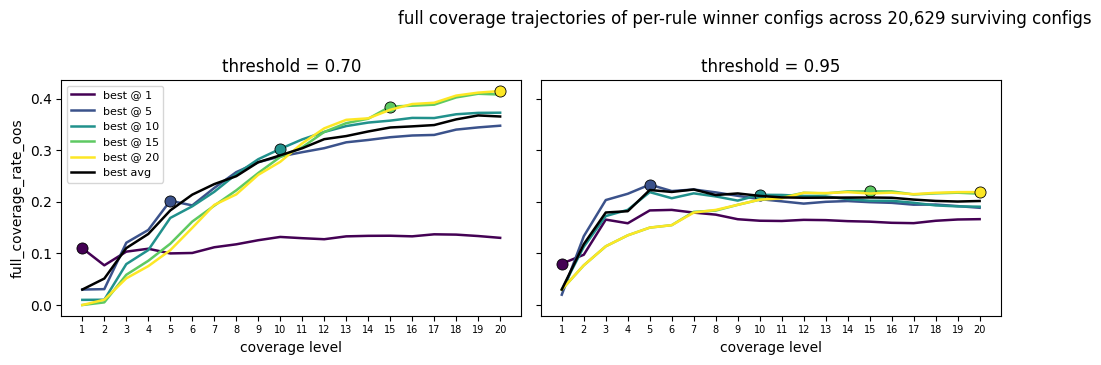


Winner configs per (threshold, rule):
 threshold      rule s1_family s1_exposure_mode                                                                 s1_cov s2_family s2_exposure_mode                                                                  s2_cov  bulk_family bulk_exposure_mode                                                                bulk_cov        tail_family tail_exposure_mode                                                               tail_cov
      0.70  best @ 1     logit             free {"basin": false, "is_island": false, "sdi": true, "wind_speed": false}     logit             free {"basin": false, "is_island": false, "sdi": false, "wind_speed": false} scaled_logit               free {"basin": false, "is_island": false, "sdi": false, "wind_speed": false}           gpd_cens               free {"basin": false, "is_island": false, "sdi": false, "wind_speed": true}
      0.70  best @ 5     logit             free  {"basin": true, "is_island": false, "sdi": true, "

In [6]:
winner_records = H.threshold_winner_panels(df_oos)
plt.show()

print('\nWinner configs per (threshold, rule):')
print(winner_records.to_string(index=False))

## Per-row diagnostics — `mid` reconstruction

`dh_results.parquet` stores spec attributes but not the MD5 `model_id` used
as the filename prefix in `model_predictions/`. Rebuild it via a lookup
against this run's manifest, then attach as a `mid` column on `df_oos`.

In [7]:
import json
from idd_tc_mortality.cache import model_id as compute_model_id

manifest = json.loads(MANIFEST_PATH.read_text())

# (component, threshold, family, exposure_mode, cov_str) -> full spec dict.
spec_lookup: dict[tuple, dict] = {}
for cid, spec in manifest.items():
    if not isinstance(spec, dict):
        continue
    if spec.get('fold_tag', 'is') != 'is':
        continue
    cov_str = json.dumps(spec.get('covariate_combo', {}), sort_keys=True)
    key = (
        spec.get('component'),
        spec.get('threshold_quantile'),  # None for s1
        spec.get('family'),
        spec.get('exposure_mode'),
        cov_str,
    )
    spec_lookup[key] = spec


def _row_to_mid(row: pd.Series) -> str:
    q = row['threshold_quantile']
    s1 = spec_lookup[('s1',   None, row['s1_family'],   row['s1_exposure_mode'],   row['s1_cov'])]
    s2 = spec_lookup[('s2',   q,    row['s2_family'],   row['s2_exposure_mode'],   row['s2_cov'])]
    bk = spec_lookup[('bulk', q,    row['bulk_family'], row['bulk_exposure_mode'], row['bulk_cov'])]
    tl = spec_lookup[('tail', q,    row['tail_family'], row['tail_exposure_mode'], row['tail_cov'])]
    return compute_model_id(s1, s2, bk, tl)


df_oos['mid'] = df_oos.apply(_row_to_mid, axis=1)
print(f'mid attached. {df_oos["mid"].nunique():,} unique mids across {len(df_oos):,} configs.')

mid attached. 20,629 unique mids across 20,629 configs.


## Prediction index + loader (shards only; flat root resolved lazily)

Final-run predictions live in the 188 `task_*` shard dirs (per-fold AND batched
files from the retry waves) plus a flat root holding early attempts' per-fold
files. **Never readdir the flat root**: it absorbed the write-saturation saga's
churn (killed tasks leak atomic-write tmp files) and streams at ~650 entries/s
(~30x slower than a clean dir — 18+ min, measured 2026-08-03). Instead, index
the clean shard dirs only, and resolve any flat-only mid lazily with exact
`exists()` probes — a handful of stats for the configs actually loaded, no
directory listing. Batched files (all fold_tags stacked) are read once per
config; prediction frames are self-contained, only `storm_id`/`deaths` are
attached positionally from `input.parquet`.

In [8]:
import os, re, time

_PRED_RE = re.compile(r'^([0-9a-f]{32})(?:_(.+))?_predictions\.parquet$')
FOLD_TAGS = ['insample'] + [f'oos_seed{i}' for i in range(5)]


def build_pred_index(model_pred_dir):
    """Shard dirs only — the flat root is resolved lazily per-mid (it holds
    leaked tmp churn from killed early attempts; never readdir it)."""
    t0 = time.time(); idx = {}; n = 0
    shards = sorted(str(p) for p in Path(model_pred_dir).glob('task_*'))
    for i, shard in enumerate(shards):
        for e in os.scandir(shard):
            m = _PRED_RE.match(e.name)
            if m:
                idx.setdefault(m.group(1), {})[m.group(2)] = e.path
                n += 1
        if (i + 1) % 40 == 0:
            print(f'  shard {i+1}/{len(shards)}: {n:,} files ({time.time()-t0:.0f}s)', flush=True)
    print(f'  {n:,} files across {len(shards)} shards in {time.time()-t0:.0f}s')
    return idx


PRED_INDEX = build_pred_index(MODEL_PRED_DIR)


def _resolve_flat(mid):
    """Lazy flat-root fallback: probe exact filenames (few stats, no readdir)."""
    files = {}
    b = MODEL_PRED_DIR / f'{mid}_predictions.parquet'
    if b.exists():
        files[None] = str(b)
    else:
        for tag in FOLD_TAGS:
            p = MODEL_PRED_DIR / f'{mid}_{tag}_predictions.parquet'
            if p.exists():
                files[tag] = str(p)
    if not files:
        raise FileNotFoundError(f'no predictions for {mid} in shards or flat root')
    PRED_INDEX[mid] = files
    return files


def load_pred_frames(mid):
    """{fold_tag: prediction frame}, storm_id/deaths attached positionally."""
    files = PRED_INDEX.get(mid) or _resolve_flat(mid)
    if None in files:   # batched: one read serves every fold_tag
        stacked = pd.read_parquet(files[None])
        groups = {t: g.reset_index(drop=True)
                  for t, g in stacked.groupby('fold_tag', sort=False)}
    else:               # per-fold files
        groups = {t: pd.read_parquet(pth) for t, pth in files.items()}
    out = {}
    for tag, g in groups.items():
        if len(g) != len(obs):
            raise ValueError(f'{mid} {tag}: {len(g):,} rows != input {len(obs):,}')
        g = g.copy()
        g['storm_id'] = obs['storm_id'].values
        g['deaths']   = obs['deaths'].values
        out[tag] = g
    return out


def load_pred(mid, fold_tag):
    """One fold's predictions joined to full input metadata (winner deep-dives)."""
    g = load_pred_frames(mid)[fold_tag]
    j = obs.copy()
    j['predicted_rate'] = g['predicted_rate'].values
    for col in ('heldout_fold_tag', 'threshold_rate', 'fold_tag'):
        if col in g.columns:
            j[col] = g[col].values
    return j


n_batched = sum(1 for v in PRED_INDEX.values() if None in v)
have = df_oos['mid'].isin(PRED_INDEX).sum()
print(f'{len(PRED_INDEX):,} mids in shard index ({n_batched:,} batched); '
      f'{have:,} of {len(df_oos):,} post-cull configs shard-covered '
      f'(rest resolve lazily from the flat root)')

  shard 40/188: 126,651 files (1s)
  shard 80/188: 329,526 files (1s)
  shard 120/188: 540,485 files (2s)
  shard 160/188: 637,752 files (2s)
  866,634 files across 188 shards in 2s
154,000 mids in shard index (103,999 batched); 20,629 of 20,629 post-cull configs shard-covered (rest resolve lazily from the flat root)


In [9]:
from concurrent.futures import ProcessPoolExecutor, as_completed

N_SWEEP   = [0, 2, 5, 10, 25]
N_WORKERS = 12


def _per_storm(pred_df):
    pred_df = pred_df.assign(pred_deaths=pred_df['predicted_rate'] * pred_df['exposed'])
    return (pred_df.groupby('storm_id', as_index=False)
            .agg(obs=('deaths', 'sum'), pred=('pred_deaths', 'sum'))
            .sort_values('obs', ascending=False))


def _trimmed(per_storm, drop_top_n):
    keep = per_storm.iloc[drop_top_n:]
    denom = keep['obs'].sum()
    return float(keep['pred'].sum() / denom) if denom > 0 else float('nan')


def trimmed_ratios_one_config(mid):
    frames  = load_pred_frames(mid)
    ps_is    = _per_storm(frames['insample']) if 'insample' in frames else None
    ps_seeds = [_per_storm(f) for tag, f in sorted(frames.items())
                if tag.startswith('oos_seed')]
    rows = []
    for n in N_SWEEP:
        per_seed = [_trimmed(ps, n) for ps in ps_seeds]
        rows.append({
            'mid': mid,
            'drop_top_n': n,
            'ratio_mean':   float(np.nanmean(per_seed)) if per_seed else float('nan'),
            'ratio_median': float(np.nanmedian(per_seed)) if per_seed else float('nan'),
            'ratio_is':     _trimmed(ps_is, n) if ps_is is not None else float('nan'),
        })
    return rows



In [10]:
cull = False
if cull:
    force_s1_cov = '{"basin": true, "is_island": true, "sdi": true, "wind_speed": true}'
    force_s2_cov = '{"basin": true, "is_island": true, "sdi": true, "wind_speed": true}'
    sub_df_oos = df_oos[(df_oos['s1_cov'] == force_s1_cov) & (df_oos['s2_cov'] == force_s2_cov)].copy()
    print(f'{len(sub_df_oos):,} configs after forcing s1/s2 covariates')
else:
    sub_df_oos = df_oos.copy()



# ---- decode cov patterns (needed by the structural cuts below) --------------
def decode_cov_columns(df):
    for stage in ['s1', 's2', 'bulk', 'tail']:
        col = f'{stage}_cov'
        for cov in ['basin', 'is_island', 'sdi', 'wind_speed']:
            df[f'{stage}_{cov}'] = df[col].apply(
                lambda x: (x if isinstance(x, dict) else json.loads(x)).get(cov, False)
            )
    return df

sub_df_oos = decode_cov_columns(sub_df_oos)
for stage in ['s1', 's2', 'bulk', 'tail']:
    covs = ['basin', 'is_island', 'sdi', 'wind_speed']
    sub_df_oos[f'{stage}_pattern'] = sub_df_oos.apply(
        lambda row: '+'.join(c for c in covs if row[f'{stage}_{c}']), axis=1
    )

# # ---- structural cut 1: bulk is intercept-only or mirrors the tail -----------
# keep = ((sub_df_oos['bulk_pattern'] == sub_df_oos['tail_pattern'])
#         | (sub_df_oos['bulk_pattern'] == ''))
# sub_df_oos = sub_df_oos[keep].copy()
# print(f'{len(sub_df_oos):,} after bulk-pattern cut')

# # ---- structural cut 2: collapse bulk clones — one row per formulation -------
# # A formulation = (threshold, tail_family, tail_exposure_mode, tail_pattern);
# # with s1/s2 forced, the surviving bulk variants only wiggle metrics in the
# # 3rd decimal (they ranked as interchangeable blocks). Keep the most
# # parsimonious variant (intercept-only bulk, then 'free' exposure) and record
# # how many clones it stands for.
# formulation = ['threshold_quantile', 'tail_family', 'tail_exposure_mode', 'tail_pattern']
# n_var = sub_df_oos.groupby(formulation).size().rename('n_bulk_variants')
# bulk_k = (sub_df_oos['bulk_pattern'].str.count(r'\+')
#           + (sub_df_oos['bulk_pattern'] != '').astype(int))
# sub_df_oos = (sub_df_oos.assign(_bulk_k=bulk_k)
#     .sort_values(['_bulk_k', 'bulk_exposure_mode'])
#     .drop_duplicates(formulation)
#     .merge(n_var.reset_index(), on=formulation)
#     .drop(columns='_bulk_k'))
# print(f'-> {len(sub_df_oos):,} distinct formulations '
#       f'(max clone-family collapsed: {sub_df_oos["n_bulk_variants"].max()})')

# ---- trimmed sweep, survivors only (fewer prediction reads) ------------------
sub_records = []
mids = sub_df_oos['mid'].tolist()
with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = [pool.submit(trimmed_ratios_one_config, m) for m in mids]
    for i, fut in enumerate(as_completed(futures), start=1):
        sub_records.extend(fut.result())
        if i % 500 == 0 or i == len(mids):
            print(f'  trimmed-ratio: {i}/{len(mids)} configs done')

sub_recs    = pd.DataFrame(sub_records)
trim_mean   = sub_recs.pivot(index='mid', columns='drop_top_n', values='ratio_mean')
trim_median = sub_recs.pivot(index='mid', columns='drop_top_n', values='ratio_median')
trim_is     = sub_recs.pivot(index='mid', columns='drop_top_n', values='ratio_is')
trim_mean.columns   = [f'trim_n={n}_oos_mean'   for n in trim_mean.columns]
trim_median.columns = [f'trim_n={n}_oos_median' for n in trim_median.columns]
trim_is.columns     = [f'trim_n={n}_is'         for n in trim_is.columns]

stale = [c for c in sub_df_oos.columns if c.startswith('trim_n=')]
sub_df_oos = (sub_df_oos.drop(columns=stale)
    .merge(trim_is,     left_on='mid', right_index=True, how='left')
    .merge(trim_mean,   left_on='mid', right_index=True, how='left')
    .merge(trim_median, left_on='mid', right_index=True, how='left'))


  trimmed-ratio: 500/20629 configs done
  trimmed-ratio: 1000/20629 configs done
  trimmed-ratio: 1500/20629 configs done
  trimmed-ratio: 2000/20629 configs done
  trimmed-ratio: 2500/20629 configs done
  trimmed-ratio: 3000/20629 configs done
  trimmed-ratio: 3500/20629 configs done
  trimmed-ratio: 4000/20629 configs done
  trimmed-ratio: 4500/20629 configs done
  trimmed-ratio: 5000/20629 configs done
  trimmed-ratio: 5500/20629 configs done
  trimmed-ratio: 6000/20629 configs done
  trimmed-ratio: 6500/20629 configs done
  trimmed-ratio: 7000/20629 configs done
  trimmed-ratio: 7500/20629 configs done
  trimmed-ratio: 8000/20629 configs done
  trimmed-ratio: 8500/20629 configs done
  trimmed-ratio: 9000/20629 configs done
  trimmed-ratio: 9500/20629 configs done
  trimmed-ratio: 10000/20629 configs done
  trimmed-ratio: 10500/20629 configs done
  trimmed-ratio: 11000/20629 configs done
  trimmed-ratio: 11500/20629 configs done
  trimmed-ratio: 12000/20629 configs done
  trimmed-ra

In [14]:
metrics_to_use = {
    # ---- S1 (binary: P(deaths >= 1)) ----
    # 's1_auroc_oos':                  'higher',
    # 's1_brier_oos':                'lower',

    # ---- S2 (binary: P(rate >= thresh | deaths >= 1)) ----
    # 's2_auroc_oos':                  'higher',
    # 's2_brier_oos':                'lower',

    # ---- Bulk (regression on rate < thresh) ----
    'bulk_mae_rate_oos':             'lower',
    # 'bulk_cor_rate_oos':           'higher',

    # ---- Tail (regression on rate >= thresh) ----
    'tail_mae_rate_oos':             'lower',
    # 'tail_rmse_rate_oos':          'lower',
    'tail_cor_rate_oos':             'higher',

    # ---- Full (unconditional E[rate]) ----
    'full_mae_rate_oos':             'lower',
    # 'full_rmse_rate_oos':          'lower',
    'full_cor_rate_oos':             'higher',
    'full_zero_acc_oos':             'higher',
    'full_pred_obs_ratio_oos':       'calib',
    'full_coverage_rate_1_oos':      'higher',
    'full_coverage_count_1_oos':     'higher',
    'full_coverage_rate_5_oos':      'higher',
    'full_coverage_count_5_oos':     'higher',
    'full_coverage_rate_10_oos':      'higher',
    'full_coverage_count_10_oos':     'higher',
    'full_coverage_rate_20_oos':      'higher',
    'full_coverage_count_20_oos':     'higher',

    # ---- Forward (stage-conditional aggregate) ----
    'fwd_mae_rate_oos':              'lower',
    'fwd_pred_obs_ratio_oos':        'calib',
    'fwd_coverage_rate_1_oos':      'higher',
    'fwd_coverage_count_1_oos':     'higher',
    'fwd_coverage_rate_5_oos':      'higher',
    'fwd_coverage_count_5_oos':     'higher',
    'fwd_coverage_rate_10_oos':      'higher',
    'fwd_coverage_count_10_oos':     'higher',
    'fwd_coverage_rate_20_oos':      'higher',
    'fwd_coverage_count_20_oos':     'higher',

    # ---- Storm-level (pool-only columns) ----
    'trim_n=0_is':                  'calib',
    'trim_n=2_oos_median':          'calib',
    'trim_n=2_oos_mean':          'calib',
    'trim_n=2_is':                  'calib',
    'trim_n=5_oos_median':          'calib',
    'trim_n=5_oos_mean':          'calib',
    'trim_n=5_is':                  'calib',
    'trim_n=10_oos_median':          'calib',
    'trim_n=10_oos_mean':          'calib',
    'trim_n=10_is':                  'calib',
    'trim_n=25_oos_median':          'calib',
    'trim_n=25_oos_mean':          'calib',
    'trim_n=25_is':                  'calib',
}

calib_present   = [k for k, v in metrics_to_use.items()
                   if v == 'calib' and k in sub_df_oos.columns]
metrics_present = {k: v for k, v in metrics_to_use.items()
                   if k in sub_df_oos.columns}

print(f'Active rank metrics ({len(metrics_present)}):')
for m, d in metrics_present.items():
    print(f'  {m:35s}  {d}')
print(f'\nActive calibration metrics ({len(calib_present)}):')
for c in calib_present:
    print(f'  {c}  (closer to 1.0)')

missing = [k for k in metrics_to_use if k not in sub_df_oos.columns]
if missing:
    print(f'\n[note] {len(missing)} requested metrics not in sub_df_oos (skipped): {missing}')

Active rank metrics (38):
  bulk_mae_rate_oos                    lower
  tail_mae_rate_oos                    lower
  tail_cor_rate_oos                    higher
  full_mae_rate_oos                    lower
  full_cor_rate_oos                    higher
  full_zero_acc_oos                    higher
  full_pred_obs_ratio_oos              calib
  full_coverage_rate_1_oos             higher
  full_coverage_count_1_oos            higher
  full_coverage_rate_5_oos             higher
  full_coverage_count_5_oos            higher
  full_coverage_rate_10_oos            higher
  full_coverage_count_10_oos           higher
  full_coverage_rate_20_oos            higher
  full_coverage_count_20_oos           higher
  fwd_mae_rate_oos                     lower
  fwd_pred_obs_ratio_oos               calib
  fwd_coverage_rate_1_oos              higher
  fwd_coverage_count_1_oos             higher
  fwd_coverage_rate_5_oos              higher
  fwd_coverage_count_5_oos             higher
  fwd_coverage

In [19]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

def similarity_groups(df, filters=None, metric_cols=None, t=1.0, ref_df=None):
    """Slice df by `filters`, then group rows whose members differ by <= t SD
    on EVERY metric (complete linkage + Chebyshev on z-scores).

    filters : {col: value or list} e.g. {'tail_family': 'log_logistic_trunc'}
    ref_df  : frame whose mean/SD define the yardstick (default: the un-sliced df,
              so '1 SD' means the same thing across different slices)
    Returns (sliced df with 'sim_group', summary of groups with n > 1).
    """
    sub = df
    for col, val in (filters or {}).items():
        vals = val if isinstance(val, (list, set, tuple)) else [val]
        sub = sub[sub[col].isin(vals)]
    sub = sub.copy()
    mcols = list(metric_cols or final_metrics_present)

    # Yardstick: per-metric mean/SD from the un-sliced (or explicit ref) frame.
    ref = ref_df if ref_df is not None else df
    mu, sd = ref[mcols].mean(), ref[mcols].std(ddof=1)

    # Drop metrics that can't carry a yardstick: zero/NaN SD, or SD vanishing
    # relative to the mean (catches ~constant metrics even when mu is large).
    dead = sd[(sd == 0) | ~np.isfinite(sd)
              | (sd < 1e-12 * mu.abs().clip(lower=1e-300))].index.tolist()
    if dead:
        print(f'dropping ~constant metrics from the yardstick: {dead}')
        mcols = [m for m in mcols if m not in dead]
        mu, sd = mu[mcols], sd[mcols]

    Z = ((sub[mcols] - mu) / sd).to_numpy(float)

    # NaN metrics make Chebyshev distances NaN and linkage garbage — drop those rows.
    ok = np.isfinite(Z).all(axis=1)
    if not ok.all():
        print(f'dropping {(~ok).sum():,} rows with non-finite metrics from grouping')
        sub = sub[ok].copy()
        Z = Z[ok]

    if len(sub) < 2:
        sub['sim_group'] = 1
        return sub, None

    d = pdist(Z, metric='chebyshev')
    sub['sim_group'] = fcluster(linkage(d, method='complete'), t=t, criterion='distance')

    summary = (sub.groupby('sim_group')
        .agg(n=('mid', 'size'),
             thresholds=('threshold_quantile', lambda s: sorted(set(s))),
             tail_exp=('tail_exposure_mode', lambda s: sorted(set(s))),
             tail_patterns=('tail_pattern', lambda s: sorted(set(s))),
             bulk_patterns=('bulk_pattern', lambda s: sorted(set(s))[:5]))
        .sort_values('n', ascending=False))
    summary = summary[summary['n'] > 1]
    return sub, summary


In [ ]:
# # all rows with tail dist X
# g, summary = similarity_groups(sub_df_oos, {'tail_family': 'log_logistic_trunc'}, t = 0.05)
# n_dupes = (summary['n'] - 1).sum()
# print(f'{n_dupes:,} rows are exact-for-all-purposes duplicates of another row')

# # keep the most parsimonious member of each group (plus all singletons)
# bulk_k = g['bulk_pattern'].str.count(r'\+') + (g['bulk_pattern'] != '').astype(int)

2,074 rows are exact-for-all-purposes duplicates of another row


In [ ]:
# # all rows with tail dist X
# g, summary = similarity_groups(sub_df_oos, {'tail_family': 'log_logistic_trunc'}, t = 0.1)
# n_dupes = (summary['n'] - 1).sum()
# print(f'{n_dupes:,} rows are exact-for-all-purposes duplicates of another row')

# # keep the most parsimonious member of each group (plus all singletons)
# print(summary)

3,382 rows are exact-for-all-purposes duplicates of another row
            n thresholds       tail_exp                     tail_patterns                                      bulk_patterns
sim_group                                                                                                                   
880        28      [0.7]  [free+weight]  [basin+is_island+sdi+wind_speed]  [, basin+is_island+sdi+wind_speed, basin+is_is...
1165       22      [0.7]  [free+weight]        [is_island+sdi+wind_speed]  [, basin+is_island+sdi+wind_speed, basin+is_is...
1100       20      [0.7]  [free+weight]                  [sdi+wind_speed]  [basin+is_island+sdi+wind_speed, basin+sdi, ba...
1551       19      [0.7]  [free+weight]                      [wind_speed]  [, basin+is_island+sdi+wind_speed, basin+is_is...
1709       19      [0.7]  [free+weight]                      [wind_speed]  [, basin+is_island+sdi+wind_speed, basin+is_is...
...        ..        ...            ...                      

In [46]:
CONFIG_ID_COLS = ['threshold_quantile',
    's1_family', 's1_exposure_mode', 's2_family', 's2_exposure_mode',
    'bulk_family', 'bulk_exposure_mode', 'tail_family', 'tail_exposure_mode',
    's1_cov', 's2_cov', 'bulk_cov', 'tail_cov']

# ---- related: drop singleton groups from g ----------------------------------
g_multi = g[g.groupby('sim_group')['sim_group'].transform('size') > 1].copy()

# ---- (a) groups whose members are the SAME config on every ID column --------
# (each row is a distinct mid, so nonzero here means duplicated rows — a bug)
n_distinct = g_multi.groupby('sim_group')[CONFIG_ID_COLS].nunique().max(axis=1)
identical = n_distinct[n_distinct == 1].index
if len(identical):
    print(f'WARNING: {len(identical)} groups are literal config duplicates — '
          f'check for a merge that multiplied rows')
g_pick = g_multi[~g_multi['sim_group'].isin(identical)].copy()

# ---- (b) parsimony pick with explicit tie-break cascade ----------------------
def n_covs(s):
    return s.str.count(r'\+') + (s != '').astype(int)

for st in ['s1', 's2', 'bulk', 'tail']:
    g_pick[f'_k_{st}'] = n_covs(g_pick[f'{st}_pattern'])
g_pick['_k_total'] = g_pick[['_k_s1', '_k_s2', '_k_bulk', '_k_tail']].sum(axis=1)

# cascade: fewest TOTAL terms; then fewest tail terms, s2, s1, bulk (handles
# "smaller in some, bigger in others"); then exposure modes alphabetically;
# then mid — explicit, arbitrary, reproducible.
sort_keys = ['_k_total', '_k_tail', '_k_s2', '_k_s1', '_k_bulk',
             'tail_exposure_mode', 'bulk_exposure_mode',
             's2_exposure_mode', 's1_exposure_mode', 'mid']

winners = (g_pick.sort_values(sort_keys)
           .drop_duplicates('sim_group')
           .drop(columns=[c for c in g_pick.columns if c.startswith('_k')]))
print(f'{g_pick["sim_group"].nunique():,} groups -> {len(winners):,} representatives')


1,147 groups -> 1,147 representatives


In [48]:
# ==== cull metric-duplicates within every tail family, then re-rank ==========
CULL_T = 0.1   # TUNE: max SD gap on every metric for two rows to count as twins

def _n_covs(s):
    return s.str.count(r'\+') + (s != '').astype(int)

_sort_keys = ['_k_total', '_k_tail', '_k_s2', '_k_s1', '_k_bulk',
              'tail_exposure_mode', 'bulk_exposure_mode',
              's2_exposure_mode', 's1_exposure_mode', 'mid']

culled_parts = []
for fam in sorted(sub_df_oos['tail_family'].unique()):
    g_fam, _ = similarity_groups(sub_df_oos, {'tail_family': fam}, t=CULL_T)
    for st in ['s1', 's2', 'bulk', 'tail']:
        g_fam[f'_k_{st}'] = _n_covs(g_fam[f'{st}_pattern'])
    g_fam['_k_total'] = g_fam[['_k_s1', '_k_s2', '_k_bulk', '_k_tail']].sum(axis=1)
    # drop_duplicates keeps the parsimony pick for multi-member groups AND
    # keeps singletons (their only row is trivially first) — no g_multi filter
    # here: unique models must survive into the ranking pool.
    fam_winners = g_fam.sort_values(_sort_keys).drop_duplicates('sim_group')
    print(f'{fam:24s} {len(g_fam):>7,} -> {len(fam_winners):>6,}')
    culled_parts.append(fam_winners)

culled_df_oos = (pd.concat(culled_parts, ignore_index=True)
                 .drop(columns=[c for c in culled_parts[0].columns
                                if c.startswith('_k') or c == 'sim_group']))
print(f'\nTOTAL: {len(sub_df_oos):,} -> {len(culled_df_oos):,} configs')

# ---- Kendall -> prune -> Borda/TOPSIS on the culled pool ---------------------
tau_culled = kendall_tau_heatmap(culled_df_oos, metrics_present, calib_present,
                                 plot=False, verbose=False)
culled_metrics, culled_prune_log = prune_redundant_metrics(
    tau_culled, metrics_present, threshold=0.7,
    protect=['full_pred_obs_ratio_oos'])   # drop protect= if using the library version
tau_culled = kendall_tau_heatmap(culled_df_oos, culled_metrics, calib_present,
                                 plot=False, verbose=False)

borda_culled, _  = borda_rank(culled_df_oos, culled_metrics, calib_present, plot=False)
topsis_culled, _ = topsis_rank(culled_df_oos, culled_metrics, calib_present, verbose=False)

ranked_culled = (culled_df_oos
    .merge(borda_culled[['mid', 'borda_rank', 'borda_score']],   on='mid', how='left')
    .merge(topsis_culled[['mid', 'topsis_rank', 'topsis_score']], on='mid', how='left')
    .sort_values('topsis_rank')
    .reset_index(drop=True))

cols = ['mid', 'borda_rank', 'topsis_rank', 'topsis_score', 'threshold_quantile',
        'bulk_exposure_mode', 'bulk_pattern',
        'tail_family', 'tail_exposure_mode', 'tail_pattern'] + list(culled_metrics)
ranked_culled[cols].head(20)


gamma                      1,017 ->    573
gpd_cens                   2,270 ->  1,067
log_logistic_cens          2,338 ->  1,361
log_logistic_trunc         5,231 ->  1,849
lognormal                  9,773 ->  3,297

TOTAL: 20,629 -> 8,147 configs


TypeError: prune_redundant_metrics() got an unexpected keyword argument 'protect'

In [ ]:

tau_df = kendall_tau_heatmap(sub_df_oos, metrics_present, calib_present, plot=False, verbose=False)
final_metrics_present, prune_log = prune_redundant_metrics(tau_df, metrics_present, threshold=0.7)
tau_df = kendall_tau_heatmap(sub_df_oos, final_metrics_present, calib_present, plot=False, verbose=False)

borda_df, _  = borda_rank(sub_df_oos, final_metrics_present, calib_present, plot = False)
topsis_df, _  = topsis_rank(sub_df_oos, final_metrics_present, calib_present, verbose=False)
full_sub_df_oos = sub_df_oos.merge(borda_df[['mid', 'borda_rank', 'borda_score']], on='mid', how='left')
full_sub_df_oos = full_sub_df_oos.merge(topsis_df[['mid', 'topsis_rank', 'topsis_score']], on='mid', how='left')
full_sub_df_oos = full_sub_df_oos.sort_values('topsis_rank').reset_index(drop=True)





cols = ['mid', 'borda_rank', 'borda_score', 'topsis_rank', 'topsis_score', 'threshold_quantile',
    'bulk_exposure_mode', 'bulk_pattern',
    'tail_family', 'tail_exposure_mode', 'tail_pattern',] + list(final_metrics_present)


full_sub_df_oos[cols].head(20)


step 1: |τ|=0.990  trim_n=5_is (0.306) vs trim_n=10_is (0.305)  → drop trim_n=5_is
step 2: |τ|=0.986  trim_n=5_oos_mean (0.357) vs trim_n=10_oos_mean (0.355)  → drop trim_n=5_oos_mean
step 3: |τ|=0.985  trim_n=5_oos_median (0.341) vs trim_n=10_oos_median (0.338)  → drop trim_n=5_oos_median
step 4: |τ|=0.975  trim_n=2_is (0.268) vs trim_n=10_is (0.262)  → drop trim_n=2_is
step 5: |τ|=0.970  trim_n=2_oos_mean (0.319) vs trim_n=10_oos_mean (0.311)  → drop trim_n=2_oos_mean
step 6: |τ|=0.970  trim_n=2_oos_median (0.297) vs trim_n=10_oos_median (0.289)  → drop trim_n=2_oos_median
step 7: |τ|=0.968  trim_n=10_is (0.212) vs trim_n=25_is (0.202)  → drop trim_n=10_is
step 8: |τ|=0.936  trim_n=10_oos_median (0.253) vs trim_n=25_oos_median (0.227)  → drop trim_n=10_oos_median
step 9: |τ|=0.934  trim_n=10_oos_mean (0.238) vs trim_n=25_oos_mean (0.208)  → drop trim_n=10_oos_mean
step 10: |τ|=0.842  trim_n=25_oos_median (0.182) vs trim_n=25_oos_mean (0.185)  → drop trim_n=25_oos_mean
step 11: |τ|=0.

,mid,borda_rank,borda_score,topsis_rank,topsis_score,threshold_quantile,bulk_exposure_mode,bulk_pattern,tail_family,tail_exposure_mode,tail_pattern,bulk_mae_rate_oos,tail_mae_rate_oos,tail_cor_rate_oos,full_mae_rate_oos,full_cor_rate_oos,full_zero_acc_oos,full_pred_obs_ratio_oos,full_coverage_rate_1_oos,full_coverage_count_1_oos,full_coverage_rate_5_oos,full_coverage_count_5_oos,full_coverage_rate_10_oos,full_coverage_count_10_oos,full_coverage_count_20_oos,fwd_mae_rate_oos,fwd_pred_obs_ratio_oos,fwd_coverage_rate_1_oos,fwd_coverage_count_1_oos,fwd_coverage_count_5_oos,fwd_coverage_count_10_oos,fwd_coverage_count_20_oos,trim_n=0_is,trim_n=25_oos_median
0,fd4ea3a35c731e078a6993de587a5821,463.0,153703.5,1.0,0.636724,0.7,free+weight,is_island+sdi+wind_speed,log_logistic_trunc,free+weight,wind_speed,2.563589e-07,0.000844,0.319891,0.000097,0.023595,0.275415,1.182460,0.03,0.14,0.183333,0.212500,0.270157,0.332984,0.472441,0.000253,0.746771,0.057143,0.114286,0.19375,0.215625,0.326562,1.088091,12.654850
1,f8e7c4d7b4ea5f06414af205d9a40b01,699.0,157622.0,2.0,0.636316,0.7,free+weight,basin+is_island+sdi+wind_speed,log_logistic_trunc,free+weight,wind_speed,2.651773e-07,0.000844,0.319891,0.000097,0.023596,0.275415,1.182636,0.03,0.14,0.183333,0.212500,0.270157,0.331937,0.469816,0.000253,0.746695,0.057143,0.114286,0.19375,0.215625,0.326562,1.088179,12.652431
2,3f7c04b667c7a5ed5b9b185f2e2981f4,184.0,147393.0,3.0,0.635700,0.7,free,sdi+wind_speed,log_logistic_trunc,free+weight,wind_speed,2.358980e-07,0.000844,0.319891,0.000097,0.023626,0.275415,1.179835,0.03,0.13,0.183333,0.214583,0.270157,0.335079,0.471391,0.000253,0.743049,0.057143,0.114286,0.19375,0.212500,0.328125,1.085672,12.633097
3,c59fca852d124ece16bdebaaf05c9354,218.0,148328.5,4.0,0.635629,0.7,free,basin+sdi,log_logistic_trunc,free+weight,wind_speed,2.363795e-07,0.000844,0.319891,0.000097,0.023624,0.275415,1.180551,0.03,0.13,0.183333,0.212500,0.270157,0.334031,0.471391,0.000253,0.742920,0.057143,0.114286,0.19375,0.215625,0.328125,1.086384,12.640840
4,36c538d58b60c01cbb22a62f229a6381,225.0,148491.0,5.0,0.635436,0.7,free,basin+sdi+wind_speed,log_logistic_trunc,free+weight,wind_speed,2.362372e-07,0.000844,0.319891,0.000097,0.023625,0.275415,1.179866,0.03,0.13,0.183333,0.214583,0.270157,0.332984,0.470866,0.000253,0.743119,0.057143,0.114286,0.19375,0.212500,0.328125,1.085672,12.633296
5,58c2820364cd9f40d5e72c83290c9109,626.0,156432.0,6.0,0.635346,0.7,free+weight,is_island+wind_speed,log_logistic_trunc,free+weight,wind_speed,2.600832e-07,0.000844,0.319891,0.000097,0.023629,0.275257,1.176113,0.03,0.13,0.183333,0.208333,0.270157,0.332984,0.469291,0.000253,0.741288,0.057143,0.114286,0.19375,0.215625,0.326562,1.081620,12.591823
6,aa70a04fdd40258942d5963f8c80532d,587.0,155711.5,7.0,0.635299,0.7,free+weight,wind_speed,log_logistic_trunc,free+weight,wind_speed,2.595710e-07,0.000844,0.319891,0.000097,0.023629,0.275257,1.176006,0.03,0.13,0.183333,0.206250,0.270157,0.332984,0.469291,0.000253,0.741263,0.057143,0.114286,0.19375,0.215625,0.328125,1.081569,12.590336
7,e04e8cd9c67e447d32722b5e8bc497d5,188.0,147536.0,8.0,0.635296,0.7,free,sdi,log_logistic_trunc,free+weight,wind_speed,2.349851e-07,0.000844,0.319891,0.000097,0.023626,0.275415,1.180176,0.03,0.13,0.183333,0.212500,0.270157,0.334031,0.471391,0.000253,0.742978,0.057143,0.114286,0.19375,0.212500,0.328125,1.086039,12.635186
8,a879734d56e92147fc470c25616745a5,447.0,153438.5,9.0,0.635268,0.7,free+weight,sdi+wind_speed,log_logistic_trunc,free+weight,wind_speed,2.558993e-07,0.000844,0.319891,0.000097,0.023596,0.275257,1.182242,0.03,0.13,0.183333,0.212500,0.270157,0.332984,0.471391,0.000253,0.746489,0.057143,0.114286,0.19375,0.215625,0.328125,1.087919,12.653891
9,8dd82c9750bb0f53203ee9d088a24934,619.0,156235.0,10.0,0.634826,0.7,free+weight,,log_logistic_trunc,free+weight,wind_speed,2.585907e-07,0.000844,0.319891,0.000097,0.023621,0.275257,1.177006,0.03,0.13,0.183333,0.208333,0.270157,0.334031,0.469291,0.000253,0.740642,0.057143,0.114286,0.19375,0.212500,

In [ ]:
full_sub_df_oos[full_sub_df_oos['threshold_quantile'] == 0.95][cols].head(20)

,mid,borda_rank,borda_score,topsis_rank,topsis_score,threshold_quantile,bulk_exposure_mode,bulk_pattern,tail_family,tail_exposure_mode,tail_pattern,bulk_mae_rate_oos,tail_mae_rate_oos,tail_cor_rate_oos,full_cor_rate_oos,full_zero_acc_oos,full_pred_obs_ratio_oos,full_coverage_rate_1_oos,full_coverage_count_1_oos,full_coverage_rate_5_oos,full_coverage_rate_10_oos,full_coverage_count_10_oos,full_coverage_rate_20_oos,full_coverage_count_20_oos,fwd_mae_rate_oos,fwd_coverage_rate_1_oos,fwd_coverage_count_1_oos,fwd_coverage_count_10_oos,trim_n=5_is
11,c6f5db48e04bf81c0de5b945f98650f3,12.0,157.5,12.0,0.375095,0.95,free+weight,sdi+wind_speed,log_logistic_cens,free+weight,sdi+wind_speed,0.000009,0.004782,-0.195921,0.022972,0.372490,0.758192,0.03,0.00,0.141667,0.191623,0.229319,0.211024,0.421522,0.00025,0.028571,0.0,0.121875,0.931086
12,234ea8db9c1a895d0dd477d2c647ac73,13.0,181.5,13.0,0.298770,0.95,free+weight,,lognormal,excluded,basin+sdi,0.000009,0.008372,-0.418133,0.019889,0.183399,0.751070,0.00,0.01,0.181250,0.192670,0.179058,0.176903,0.352231,0.00025,0.000000,0.0,0.140625,4.223134


In [ ]:
from idd_tc_mortality.fit.fit_component import fit_one_component

def show_component_fit(row, stage='bulk'):
    q = None if stage == 's1' else row['threshold_quantile']
    spec = spec_lookup[(stage, q, row[f'{stage}_family'],
                        row[f'{stage}_exposure_mode'], row[f'{stage}_cov'])]
    r = fit_one_component(spec, data)
    print(f"{stage}: {row[f'{stage}_family']} / {row[f'{stage}_exposure_mode']} / "
          f"{row[f'{stage}_pattern'] or '(intercept-only)'}")
    print(f"  converged={r.converged}  fit_error={r.meta.get('fit_error')}")
    for name, val in zip(r.param_names, r.params):
        print(f'  {name:15s} {val:+.6g}')
    print()

for _, row in full_sub_df_oos.head(3).iterrows():
    show_component_fit(row, 'bulk')   # or 'tail' / 's2' / 's1'


bulk: scaled_logit / free+weight / is_island+sdi+wind_speed
  converged=True  fit_error=None
  const           +12.7331
  wind_speed      +0.0162539
  sdi             -4.02902
  is_island       +0.253745
  log_exposed     -0.715055

bulk: scaled_logit / free+weight / basin+is_island+sdi+wind_speed
  converged=True  fit_error=None
  const           +13.1657
  wind_speed      +0.0148999
  sdi             -4.3987
  basin_NA        -0.0145602
  basin_NI        -0.228623
  basin_AU        -0.50328
  basin_SI        -0.85515
  basin_SP        -1.4385
  basin_WP        -0.300995
  is_island       +0.348351
  log_exposed     -0.709969

bulk: scaled_logit / free / sdi+wind_speed
  converged=True  fit_error=None
  const           +10.7277
  wind_speed      +0.00290191
  sdi             -3.20482
  log_exposed     -0.606902



## Two-stage ranking: pre-TOPSIS pool, then storm-level machinery

The trimmed-calibration sweep reads parquets per config — affordable for
20260714's 4,608 configs, not for this grid. So: a cheap metric-only TOPSIS
picks the `TRIM_POOL_N` pool, and only the pool pays the storm-level cost.
Configs outside the pool keep NaN trim columns and drop out of the final
ranking (which runs on the pool).

In [ ]:
TRIM_POOL_N = 4000   # TUNE: size of the storm-level pool

pre_metrics = {
    'tail_mae_rate_oos':         'lower',
    'tail_cor_rate_oos':         'higher',
    'full_mae_rate_oos':         'lower',
    'full_cor_rate_oos':         'higher',
    'full_zero_acc_oos':         'higher',
    'full_pred_obs_ratio_oos':   'calib',
    'full_coverage_rate_10_oos': 'higher',
    'fwd_coverage_rate_10_oos':  'higher',
}
pre_calib   = [k for k, v in pre_metrics.items() if v == 'calib' and k in df_oos.columns]
pre_present = {k: v for k, v in pre_metrics.items() if k in df_oos.columns}

pre_topsis, _ = topsis_rank(df_oos, pre_present, pre_calib, verbose=False)
pool_mids = set(pre_topsis.sort_values('topsis_rank')['mid'].head(TRIM_POOL_N))
df_pool = df_oos[df_oos['mid'].isin(pool_mids)].copy()
print(f'storm-level pool: {len(df_pool):,} of {len(df_oos):,} configs')
print('\npool composition per (threshold, tail_family):')
print(df_pool.groupby(['threshold_quantile', 'tail_family']).size().to_string())

storm-level pool: 4,000 of 100,111 configs

pool composition per (threshold, tail_family):
threshold_quantile  tail_family       
0.7                 log_logistic_trunc    1351
                    lognormal             2649


## Drop-top-N trimmed calibration ratio

For every pool config, the obs/pred ratio after dropping the top-N storms by
observed deaths, N in {0, 5, 10, 25}. A config near 1 at `trim_n=0` but far at
`trim_n=5` (or vice versa) is mega-event-only or bulk-only calibrated; we want
configs near 1 across the sweep. Reads each config's predictions ONCE via the
index (batched = literally one parquet read).

In [ ]:

records = []
mids = df_pool['mid'].tolist()
with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = [pool.submit(trimmed_ratios_one_config, m) for m in mids]
    for i, fut in enumerate(as_completed(futures), start=1):
        records.extend(fut.result())
        if i % 500 == 0 or i == len(mids):
            print(f'  trimmed-ratio: {i}/{len(mids)} configs done')

  trimmed-ratio: 500/4000 configs done
  trimmed-ratio: 1000/4000 configs done
  trimmed-ratio: 1500/4000 configs done
  trimmed-ratio: 2000/4000 configs done
  trimmed-ratio: 2500/4000 configs done
  trimmed-ratio: 3000/4000 configs done
  trimmed-ratio: 3500/4000 configs done
  trimmed-ratio: 4000/4000 configs done


In [ ]:
recs = pd.DataFrame(records)

trim_df_mean   = recs.pivot(index='mid', columns='drop_top_n', values='ratio_mean')
trim_df_median = recs.pivot(index='mid', columns='drop_top_n', values='ratio_median')
trim_df_is     = recs.pivot(index='mid', columns='drop_top_n', values='ratio_is')

trim_df_mean.columns   = [f'trim_n={n}_oos_mean'   for n in trim_df_mean.columns]
trim_df_median.columns = [f'trim_n={n}_oos_median' for n in trim_df_median.columns]
trim_df_is.columns     = [f'trim_n={n}_is'         for n in trim_df_is.columns]

df_oos = (df_oos
    .merge(trim_df_is,     left_on='mid', right_index=True, how='left')
    .merge(trim_df_mean,   left_on='mid', right_index=True, how='left')
    .merge(trim_df_median, left_on='mid', right_index=True, how='left')
)
# Refresh the pool view so it carries the trim columns.
df_pool = df_oos[df_oos['mid'].isin(pool_mids)].copy()
print(f'Trim columns merged. df_oos cols: {df_oos.shape[1]}; pool rows: {len(df_pool):,}')

Trim columns merged. df_oos cols: 145; pool rows: 4,000


## IS / OOS divergence

`is_oos_ratio_n=*` = `trim_n=*_is` / `trim_n=*_oos_median`. Near 1 = IS
calibration carries OOS. Also the max/mean |log| deviation of the OOS-median
trim ratios themselves across the N sweep.

In [ ]:
for n in N_SWEEP:
    df_pool[f'is_oos_ratio_n={n}'] = (
        df_pool[f'trim_n={n}_is'] / df_pool[f'trim_n={n}_oos_median']
    )

ratio_cols = [f'is_oos_ratio_n={n}' for n in N_SWEEP]
df_pool['is_oos_max_log_dev']  = np.abs(np.log(df_pool[ratio_cols])).max(axis=1)
df_pool['is_oos_mean_log_dev'] = np.abs(np.log(df_pool[ratio_cols])).mean(axis=1)

log_dev = np.abs(np.log(df_pool[[f'trim_n={n}_oos_median' for n in N_SWEEP]]))
df_pool['oos_median_max_log_dev']  = log_dev.max(axis=1)
df_pool['oos_median_mean_log_dev'] = log_dev.mean(axis=1)
print('IS/OOS divergence columns attached to df_pool.')

IS/OOS divergence columns attached to df_pool.


## Pick your own metrics

Edit the dict — comment / uncomment — to define the set used by the Kendall
heatmap and the ranking below. Direction: `'lower'` / `'higher'` /
`'calib'` (closer to 1.0). Trim columns are available now.

In [ ]:
metrics_to_use = {
    # ---- S1 (binary: P(deaths >= 1)) ----
    's1_auroc_oos':                  'higher',
    # 's1_brier_oos':                'lower',

    # ---- S2 (binary: P(rate >= thresh | deaths >= 1)) ----
    's2_auroc_oos':                  'higher',
    # 's2_brier_oos':                'lower',

    # ---- Bulk (regression on rate < thresh) ----
    'bulk_mae_rate_oos':             'lower',
    # 'bulk_cor_rate_oos':           'higher',

    # ---- Tail (regression on rate >= thresh) ----
    'tail_mae_rate_oos':             'lower',
    # 'tail_rmse_rate_oos':          'lower',
    'tail_cor_rate_oos':             'higher',

    # ---- Full (unconditional E[rate]) ----
    'full_mae_rate_oos':             'lower',
    # 'full_rmse_rate_oos':          'lower',
    'full_cor_rate_oos':             'higher',
    'full_zero_acc_oos':             'higher',
    'full_pred_obs_ratio_oos':       'calib',
    'full_coverage_rate_10_oos':     'higher',
    'full_coverage_count_10_oos':    'higher',

    # ---- Forward (stage-conditional aggregate) ----
    'fwd_mae_rate_oos':              'lower',
    'fwd_pred_obs_ratio_oos':        'calib',
    'fwd_coverage_rate_10_oos':      'higher',
    'fwd_coverage_count_10_oos':     'higher',

    # ---- Storm-level (pool-only columns) ----
    'trim_n=10_oos_median':          'calib',
    'trim_n=10_is':                  'calib',
}

calib_present   = [k for k, v in metrics_to_use.items()
                   if v == 'calib' and k in df_pool.columns]
metrics_present = {k: v for k, v in metrics_to_use.items()
                   if k in df_pool.columns}

print(f'Active rank metrics ({len(metrics_present)}):')
for m, d in metrics_present.items():
    print(f'  {m:35s}  {d}')
print(f'\nActive calibration metrics ({len(calib_present)}):')
for c in calib_present:
    print(f'  {c}  (closer to 1.0)')

missing = [k for k in metrics_to_use if k not in df_pool.columns]
if missing:
    print(f'\n[note] {len(missing)} requested metrics not in df_pool (skipped): {missing}')

Active rank metrics (17):
  s1_auroc_oos                         higher
  s2_auroc_oos                         higher
  bulk_mae_rate_oos                    lower
  tail_mae_rate_oos                    lower
  tail_cor_rate_oos                    higher
  full_mae_rate_oos                    lower
  full_cor_rate_oos                    higher
  full_zero_acc_oos                    higher
  full_pred_obs_ratio_oos              calib
  full_coverage_rate_10_oos            higher
  full_coverage_count_10_oos           higher
  fwd_mae_rate_oos                     lower
  fwd_pred_obs_ratio_oos               calib
  fwd_coverage_rate_10_oos             higher
  fwd_coverage_count_10_oos            higher
  trim_n=10_oos_median                 calib
  trim_n=10_is                         calib

Active calibration metrics (4):
  full_pred_obs_ratio_oos  (closer to 1.0)
  fwd_pred_obs_ratio_oos  (closer to 1.0)
  trim_n=10_oos_median  (closer to 1.0)
  trim_n=10_is  (closer to 1.0)


## Kendall τ — prune redundant metrics on the pool

Computing rank correlations on 4,000 configs x 17 metrics


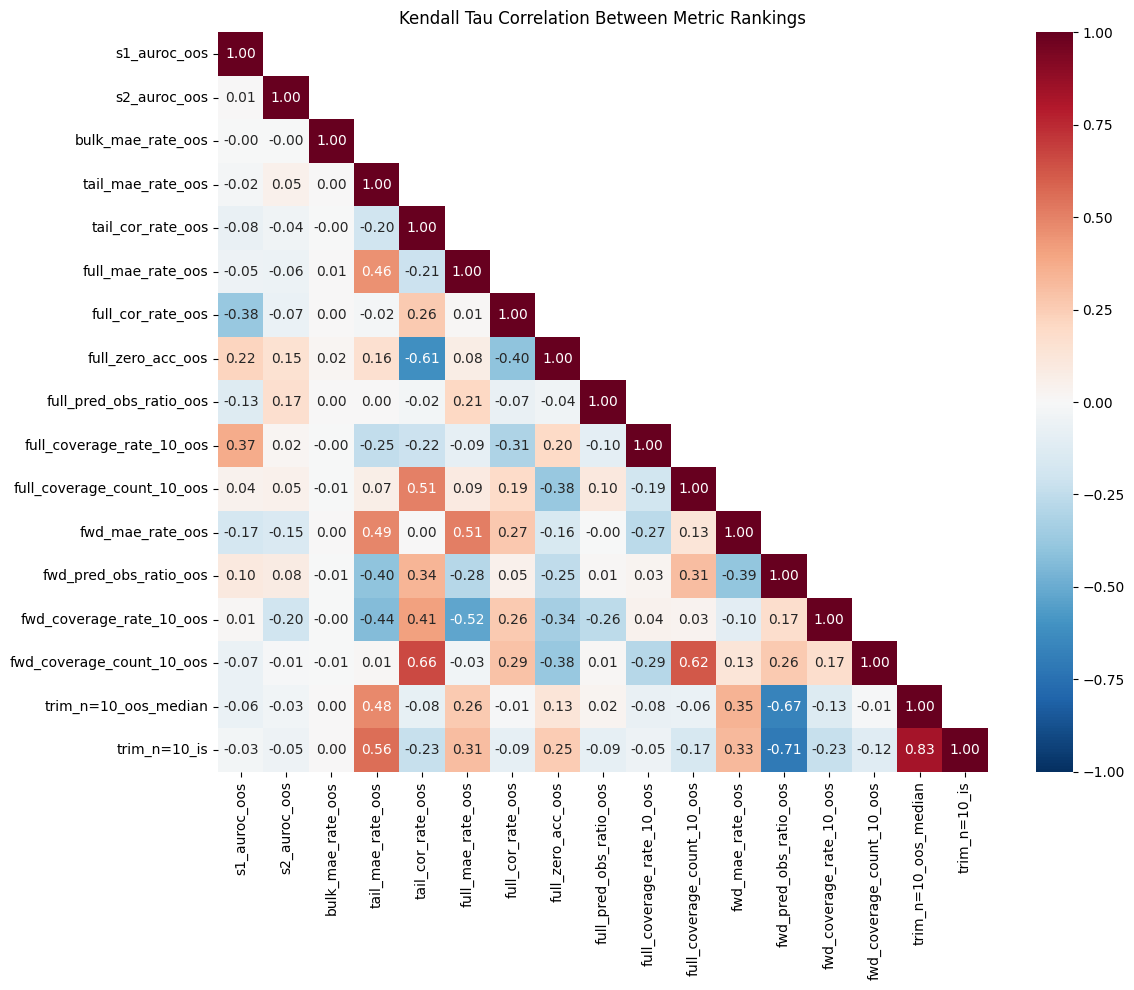

step 1: |τ|=0.829  trim_n=10_oos_median (0.159) vs trim_n=10_is (0.215)  → drop trim_n=10_is


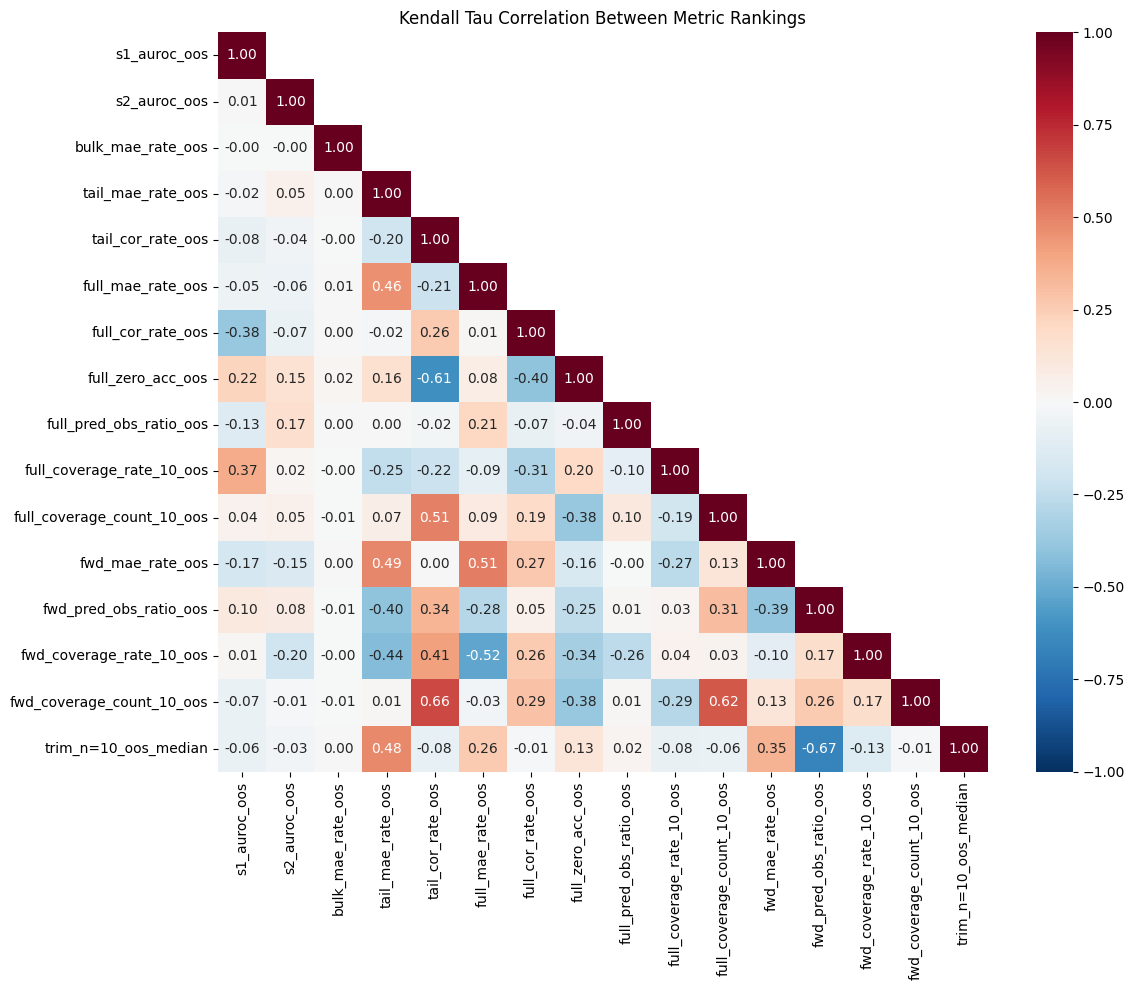

kept after pruning:
  s1_auroc_oos
  s2_auroc_oos
  bulk_mae_rate_oos
  tail_mae_rate_oos
  tail_cor_rate_oos
  full_mae_rate_oos
  full_cor_rate_oos
  full_zero_acc_oos
  full_pred_obs_ratio_oos
  full_coverage_rate_10_oos
  full_coverage_count_10_oos
  fwd_mae_rate_oos
  fwd_pred_obs_ratio_oos
  fwd_coverage_rate_10_oos
  fwd_coverage_count_10_oos
  trim_n=10_oos_median


In [ ]:
print(f'Computing rank correlations on {len(df_pool):,} configs x '
      f'{len(metrics_present)} metrics')
tau_df = kendall_tau_heatmap(df_pool, metrics_present, calib_present, plot=True, verbose=False)
final_metrics_present, prune_log = prune_redundant_metrics(tau_df, metrics_present, threshold=0.7)
tau_df = kendall_tau_heatmap(df_pool, final_metrics_present, calib_present, plot=True, verbose=False)
print('kept after pruning:')
for m in final_metrics_present:
    print(f'  {m}')

## Winners by method

Borda and TOPSIS on the pool with the pruned metric set; group summaries by
(threshold, tail_family, exposure modes).

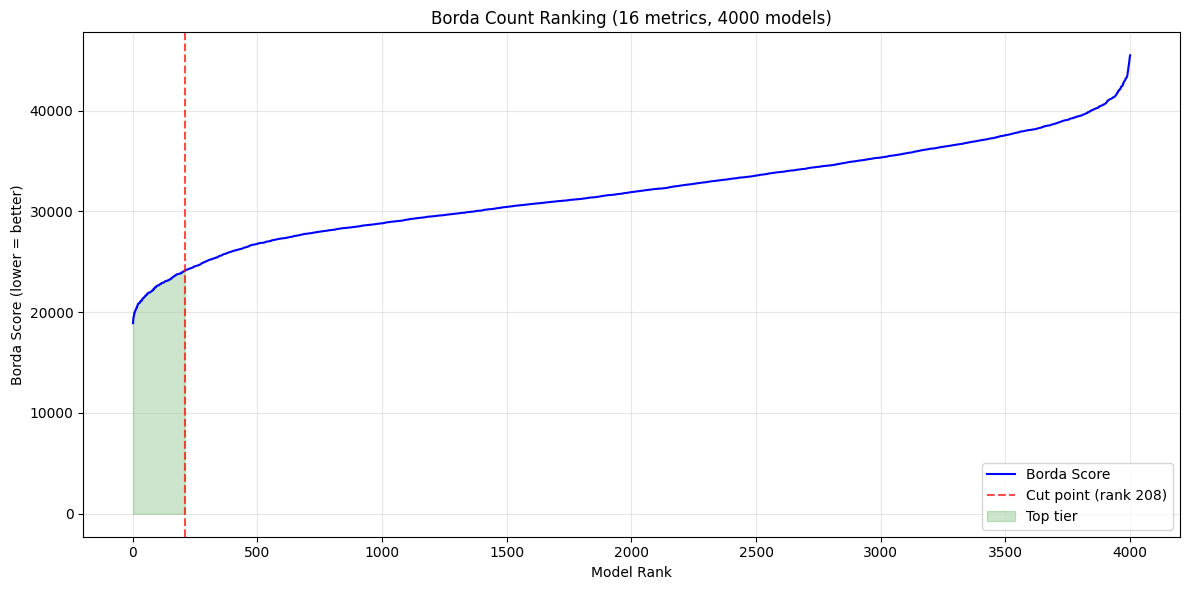


=== Borda Count Summary ===
Total models: 4000
Metrics used: 16
Suggested cutpoint: rank 208 (top 208 models)
Top tier Borda range: 18911.5 - 24097.0
Bottom tier starts at: 24104.5
Borda, top 200:
   threshold_quantile tail_family tail_exposure_mode bulk_exposure_mode  n_configs  median_rank  min_rank  median_score
0                 0.7   lognormal        free+weight               free        138         78.0       1.0      22124.25
1                 0.7   lognormal        free+weight        free+weight         62        137.0      57.0      23113.75


In [ ]:
borda_df, _  = borda_rank(df_pool, final_metrics_present, calib_present)
top_borda_df = borda_df[borda_df['borda_rank'] <= 200].copy()
summary_borda = (top_borda_df
    .groupby(['threshold_quantile', 'tail_family', 'tail_exposure_mode', 'bulk_exposure_mode'])
    .agg(
        n_configs=('borda_rank', 'count'),
        median_rank=('borda_rank', 'median'),
        min_rank=('borda_rank', 'min'),
        median_score=('borda_score', 'median'),
    )
    .reset_index()
    .sort_values('median_rank')
)
print('Borda, top 200:')
print(summary_borda.to_string())

In [ ]:
topsis_df, _  = topsis_rank(df_pool, final_metrics_present, calib_present, verbose=False)
top_topsis_df = topsis_df[topsis_df['topsis_rank'] <= 200].copy()
summary_topsis = (top_topsis_df
    .groupby(['threshold_quantile', 'tail_family', 'tail_exposure_mode', 'bulk_exposure_mode'])
    .agg(
        n_configs=('topsis_rank', 'count'),
        median_rank=('topsis_rank', 'median'),
        min_rank=('topsis_rank', 'min'),
        median_score=('topsis_score', 'median'),
    )
    .reset_index()
    .sort_values('median_rank')
)
print('TOPSIS, top 200:')
print(summary_topsis.to_string())

TOPSIS, top 200:
   threshold_quantile         tail_family tail_exposure_mode bulk_exposure_mode  n_configs  median_rank  min_rank  median_score
1                 0.7           lognormal        free+weight               free        146         73.5       1.0      0.632611
2                 0.7           lognormal        free+weight        free+weight         51        142.0      87.0      0.612134
0                 0.7  log_logistic_trunc        free+weight               free          3        178.0     170.0      0.607708


In [ ]:
import json

def decode_cov_columns(df):
    for stage in ['s1', 's2', 'bulk', 'tail']:
        col = f'{stage}_cov'
        for cov in ['basin', 'is_island', 'sdi', 'wind_speed']:
            df[f'{stage}_{cov}'] = df[col].apply(
                lambda x: (x if isinstance(x, dict) else json.loads(x)).get(cov, False)
            )
    return df

top_topsis_df = decode_cov_columns(top_topsis_df)
for stage in ['s1', 's2', 'bulk', 'tail']:
    covs = ['basin', 'is_island', 'sdi', 'wind_speed']
    top_topsis_df[f'{stage}_pattern'] = top_topsis_df.apply(
        lambda row: '+'.join(c for c in covs if row[f'{stage}_{c}']), axis=1
    )

chain_summary = (top_topsis_df
    .groupby(['s1_pattern', 's2_pattern', 'bulk_pattern', 'tail_pattern'])
    .agg(
        n=('topsis_rank', 'count'),
        median_rank=('topsis_rank', 'median'),
        min_rank=('topsis_rank', 'min'),
    )
    .reset_index()
    .sort_values('median_rank')
)
print(chain_summary.head(20).to_string())

                         s1_pattern                      s2_pattern                bulk_pattern tail_pattern  n  median_rank  min_rank
31   basin+is_island+sdi+wind_speed  basin+is_island+sdi+wind_speed                   basin+sdi   wind_speed  1         16.0      16.0
50   basin+is_island+sdi+wind_speed            basin+sdi+wind_speed                   basin+sdi   wind_speed  1         21.0      21.0
119            basin+sdi+wind_speed            basin+sdi+wind_speed            basin+wind_speed   wind_speed  1         25.0      25.0
113            basin+sdi+wind_speed            basin+sdi+wind_speed  basin+is_island+wind_speed   wind_speed  1         26.0      26.0
54   basin+is_island+sdi+wind_speed            basin+sdi+wind_speed            basin+wind_speed   wind_speed  1         27.0      27.0
102            basin+sdi+wind_speed  basin+is_island+sdi+wind_speed            basin+wind_speed   wind_speed  1         28.0      28.0
34   basin+is_island+sdi+wind_speed  basin+is_island+sd

## Picking table

Top pool configs by `topsis_rank` with stage covs, family/exposure choices,
and the storm-level diagnostics in one place. The pick rule is NOT baked in —
sort and filter interactively. Columns for the "no worse than any other"
defense: `topsis_rank`, `full_coverage_rate_*_oos`, `trim_n=*_oos_median`,
`is_oos_max_log_dev`, `oos_median_max_log_dev`.

In [ ]:
if 'topsis_rank' not in df_pool.columns:
    df_pool = df_pool.merge(
        topsis_df[['mid', 'topsis_rank', 'topsis_score']],
        on='mid', how='left',
    )

picking_cols = [
    'mid', 'threshold_quantile',
    's1_family', 's1_exposure_mode', 's1_cov',
    's2_family', 's2_exposure_mode', 's2_cov',
    'bulk_family', 'bulk_exposure_mode', 'bulk_cov',
    'tail_family', 'tail_exposure_mode', 'tail_cov',
    'topsis_rank', 'topsis_score',
    'full_pred_obs_ratio_oos',
    'full_coverage_rate_5_oos', 'full_coverage_rate_10_oos',
    'full_coverage_rate_20_oos',
    'trim_n=0_oos_median',  'trim_n=5_oos_median',
    'trim_n=10_oos_median', 'trim_n=25_oos_median',
    'trim_n=0_is', 'trim_n=5_is', 'trim_n=10_is', 'trim_n=25_is',
    'oos_median_max_log_dev', 'is_oos_max_log_dev',
]
picking_cols = [c for c in picking_cols if c in df_pool.columns]

picking_df = (df_pool[picking_cols]
              .sort_values('topsis_rank')
              .reset_index(drop=True))

TOP_N = 15
print(f'Top {TOP_N} by topsis_rank ({len(picking_df):,} pool configs total):')
print()
print(picking_df.head(TOP_N).round(3).to_string(index=False))

Top 15 by topsis_rank (4,000 pool configs total):

                             mid  threshold_quantile s1_family s1_exposure_mode                                                               s1_cov s2_family s2_exposure_mode                                                               s2_cov  bulk_family bulk_exposure_mode                                                               bulk_cov tail_family tail_exposure_mode                                                               tail_cov  topsis_rank  topsis_score  full_pred_obs_ratio_oos  full_coverage_rate_5_oos  full_coverage_rate_10_oos  full_coverage_rate_20_oos  trim_n=0_oos_median  trim_n=5_oos_median  trim_n=10_oos_median  trim_n=25_oos_median  trim_n=0_is  trim_n=5_is  trim_n=10_is  trim_n=25_is  oos_median_max_log_dev  is_oos_max_log_dev
ea394d65a666c9d00b8b2c7412756a2f                 0.7     logit             free {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}     logit             free {"basin

In [ ]:
sub_df = df_pool[df_pool['bulk_cov'].str.contains('"wind_speed": true')].copy()
sub_df = sub_df.sort_values('topsis_rank').reset_index(drop=True)

In [ ]:
sub_df[picking_cols]

,mid,threshold_quantile,s1_family,s1_exposure_mode,s1_cov,s2_family,s2_exposure_mode,s2_cov,bulk_family,bulk_exposure_mode,bulk_cov,tail_family,tail_exposure_mode,tail_cov,topsis_rank,topsis_score,full_pred_obs_ratio_oos,full_coverage_rate_5_oos,full_coverage_rate_10_oos,full_coverage_rate_20_oos,trim_n=0_oos_median,trim_n=5_oos_median,trim_n=10_oos_median,trim_n=25_oos_median,trim_n=0_is,trim_n=5_is,trim_n=10_is,trim_n=25_is,oos_median_max_log_dev,is_oos_max_log_dev
0,af6a40325cbd0f30a86a41ff7fd65b54,0.7,logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",scaled_logit,free,"{""basin"": false, ""is_island"": false, ""sdi"": tr...",lognormal,free+weight,"{""basin"": false, ""is_island"": false, ""sdi"": fa...",2.0,0.658002,0.870735,0.150000,0.261780,0.319685,0.834827,4.871679,6.365404,9.120082,0.704846,4.069797,5.311109,7.643080,2.210479,0.181077
1,b13a0fc753f399e2dec7e8187cdcd152,0.7,logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",scaled_logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",lognormal,free+weight,"{""basin"": false, ""is_island"": false, ""sdi"": fa...",4.0,0.656950,0.870915,0.150000,0.260733,0.319160,0.834935,4.872093,6.365788,9.121380,0.704983,4.070496,5.311832,7.644095,2.210621,0.181001
2,607811fe6323cb0977af438db47b9787,0.7,logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",scaled_logit,free,"{""basin"": false, ""is_island"": true, ""sdi"": tru...",lognormal,free+weight,"{""basin"": false, ""is_island"": false, ""sdi"": fa...",5.0,0.655618,0.871187,0.150000,0.260733,0.319160,0.835341,4.874676,6.369326,9.126116,0.705272,4.072325,5.314479,7.648263,2.211140,0.181059
3,7c190465a207eab24aa2d5fa83194506,0.7,logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",logit,free,"{""basin"": true, ""is_island"": true, ""sdi"": true...",scaled_logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",lognormal,free+weight,"{""basin"": false, ""is_island"": false, ""sdi"": fa...",8.0,0.655124,0.868429,0.150000,0.258639,0.318635,0.829588,4.839420,6.325552,9.043595,0.702675,4.055370,5.291164,7.608488,2.202057,0.178559
4,ea1530422acc3bbe6a14d918598bafde,0.7,logit,free,"{""basin"": true, ""is_island"": true, ""sdi"": true...",logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",scaled_logit,free,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",lognormal,free+weight,"{""basin"": false, ""is_island"": false, ""sdi"": fa...",9.0,0.654991,0.871109,0.154167,0.254450,0.318635,0.835454,4.875426,6.369972,9.125278,0.704768,4.069487,5.310283,7.641556,2.211048,0.181950
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2904,5a7664cabbbb85dd0140026b30c7a758,0.7,logit,free,"{""basin"": false, ""is_island"": true, ""sdi"": tru...",logit,free,"{""basin"": false, ""is_island"": false, ""sdi"": fa...",scaled_logit,free+weight,"{""basin"": false, ""is_island"": true, ""sdi"": fal...",log_logistic_trunc,free+weight,"{""basin"": true, ""is_island"": true, ""sdi"": true...",3995.0,0.325237,1.211346,0.179167,0.267016,0.344882,1.237442,7.057405,9.284028,13.261673,0.996381,5.740553,7.526839,10.924658,2.584878,0.216672
2905,21d1fcdc52987750b8f1c63e0e7fc50c,0.7,logit,free,"{""basin"": false, ""is_island"": true, ""sdi"": tru...",logit,free,"{""basin"": false, ""is_island"": false, ""sdi"": fa...",scaled_logit,free+weight,"{""basin"": true, ""is_island"": false, ""sdi"": tru...",log_logistic_trunc,free+weight,"{""basin"": true, ""is_island"": true, ""sdi"": true...",3996.0,0.320790,1.218367,0.179167,0.267016,0.344882,1.244210,7.095663,9.333089,13.329810,1.003608,5.781914,7.579860,10.997206,2.590003,0.214899
2906,a730f471853cf22fc459b2a5821fb00b,0.7,logit,free

In [ ]:
# Alternate view: among the top-N by topsis_rank, re-sort by IS/OOS divergence
# to surface configs whose IS calibration transfers OOS most reliably.
N_SHORTLIST = 25
shortlist = picking_df.head(N_SHORTLIST).copy()
print(f'Among top {N_SHORTLIST} by topsis_rank, sorted by oos_median_max_log_dev:')
print()
print(shortlist
      .sort_values('oos_median_max_log_dev')
      .round(3)
      .to_string(index=False))

Among top 25 by topsis_rank, sorted by oos_median_max_log_dev:

                             mid  threshold_quantile s1_family s1_exposure_mode                                                               s1_cov s2_family s2_exposure_mode                                                               s2_cov  bulk_family bulk_exposure_mode                                                               bulk_cov tail_family tail_exposure_mode                                                               tail_cov  topsis_rank  topsis_score  full_pred_obs_ratio_oos  full_coverage_rate_5_oos  full_coverage_rate_10_oos  full_coverage_rate_20_oos  trim_n=0_oos_median  trim_n=5_oos_median  trim_n=10_oos_median  trim_n=25_oos_median  trim_n=0_is  trim_n=5_is  trim_n=10_is  trim_n=25_is  oos_median_max_log_dev  is_oos_max_log_dev
5a11291b97628a7eefa90875707ca0eb                 0.7     logit             free {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}     logit            

## Next: cross-vintage universal

Winners above are per-vintage. The universal pick matches configs across the
two vintages by `CONFIG_COLS` — **never** by `mid`: the hash encodes the
data-derived `threshold_rate`, so an identical covariate/family config hashes
differently per vintage. Pattern: `notebooks/20260714_combined_final_topsis.ipynb`.